<a href="https://colab.research.google.com/github/k-nikhil-coder/100-day-ai-engineer/blob/main/day16_model_interpretability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 100 Days of AI — Day 16: Model Interpretability
## Cracking the "Black Box" of Boosted Trees using SHAP

High accuracy metrics can be deceiving if a model relies on spurious patterns or noise.
This notebook explores **TreeSHAP** (SHapley Additive exPlanations) to inspect both:
1. **Global Feature Impact**: Which real-world housing characteristics drive price predictions system-wide?
2. **Local Interpretability**: Exactly why a specific house was valued higher or lower than the regional baseline.

In [ ]:
# Install SHAP silently if running in Google Colab
!pip install shap xgboost scikit-learn pandas matplotlib -q

import shap
import xgboost as xgb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Set clean styling for visualizations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Environment successfully configured.")

Environment successfully configured.


In [ ]:
# 1. Fetch California Housing data
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target  # Median house value expressed in $100,000s

# 2. Inspect dataset features
print(f"Features: {list(X.columns)}")
print(f"Total instances: {X.shape[0]}")

# 3. 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.head(3)

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Total instances: 20640


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
14196,3.2596,33.0,5.017657,1.006421,2300.0,3.691814,32.71,-117.03
8267,3.8125,49.0,4.473545,1.041005,1314.0,1.738095,33.77,-118.16
17445,4.1563,4.0,5.645833,0.985119,915.0,2.723214,34.66,-120.48


In [ ]:
# Train an XGBoost Regressor mimicking the Day 15 hyperparameter tuning setup
xgb_reg = xgb.XGBRegressor(
    n_estimators=120,
    max_depth=5,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_reg.fit(X_train, y_train)

# Quick validation check
test_preds = xgb_reg.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, test_preds))
r2 = r2_score(y_test, test_preds)

print(f"Test RMSE: ${rmse * 100_000:,.2f}")
print(f"R² Score:  {r2:.4f}")

Test RMSE: $48,138.93
R² Score:  0.8232


## Step 1: Initialize TreeExplainer
Unlike model-agnostic kernel explainers that run slowly on large datasets, `shap.TreeExplainer` leverages
the internal tree architecture of XGBoost to compute exact Shapley values in polynomial time.

In [ ]:
# Initialize TreeExplainer
explainer = shap.TreeExplainer(xgb_reg)

# Compute explanation object on the holdout test set
shap_values = explainer(X_test)

print("Base value (Mean expected house value across training set):", f"${explainer.expected_value * 100_000:,.2f}")
print("SHAP explanation matrix shape:", shap_values.shape)

Base value (Mean expected house value across training set): $207,266.88
SHAP explanation matrix shape: (4128, 8)


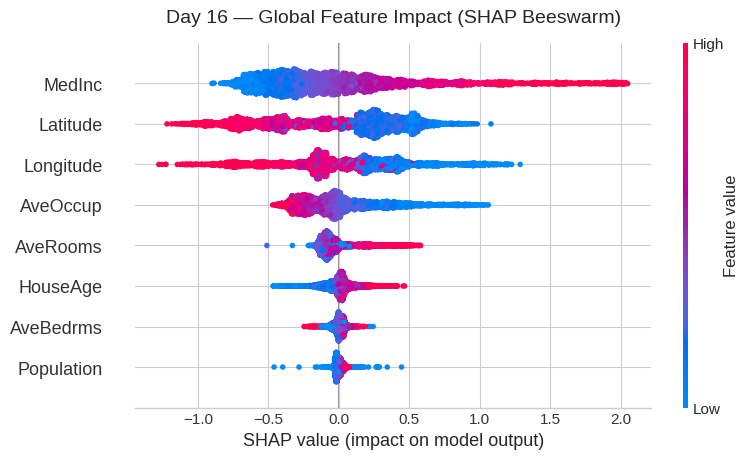

In [ ]:
plt.figure(figsize=(10, 6))
plt.title("Day 16 — Global Feature Impact (SHAP Beeswarm)", fontsize=14, pad=15)
shap.plots.beeswarm(shap_values, max_display=8, show=False)
plt.tight_layout()
plt.show()

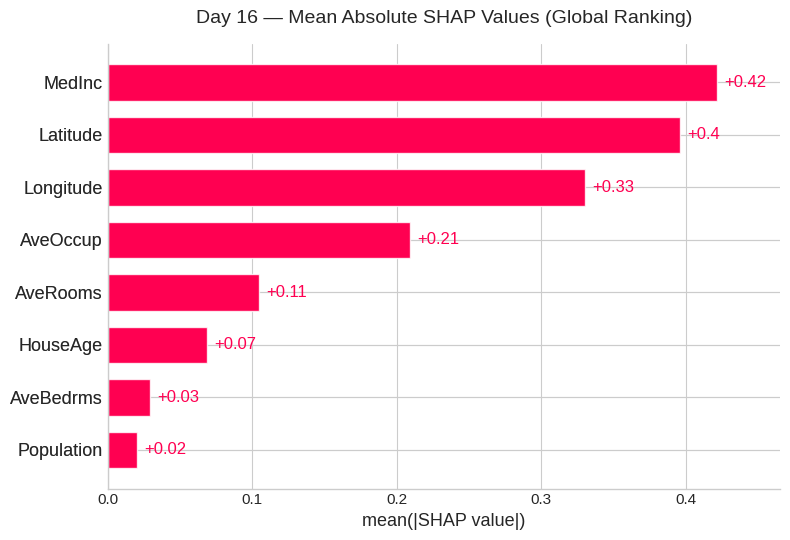

In [ ]:
plt.figure(figsize=(9, 5))
plt.title("Day 16 — Mean Absolute SHAP Values (Global Ranking)", fontsize=14, pad=15)
shap.plots.bar(shap_values, max_display=8, show=False)
plt.tight_layout()
plt.show()

## Step 2: Local Interpretability with Waterfall Plots
We inspect sample index `0` of our test set to verify exactly how individual
neighborhood parameters pushed the valuation away from the expected base value.

Sample #0:
  - Actual Valuation:    $47,700.00
  - Predicted Valuation: $37,928.11


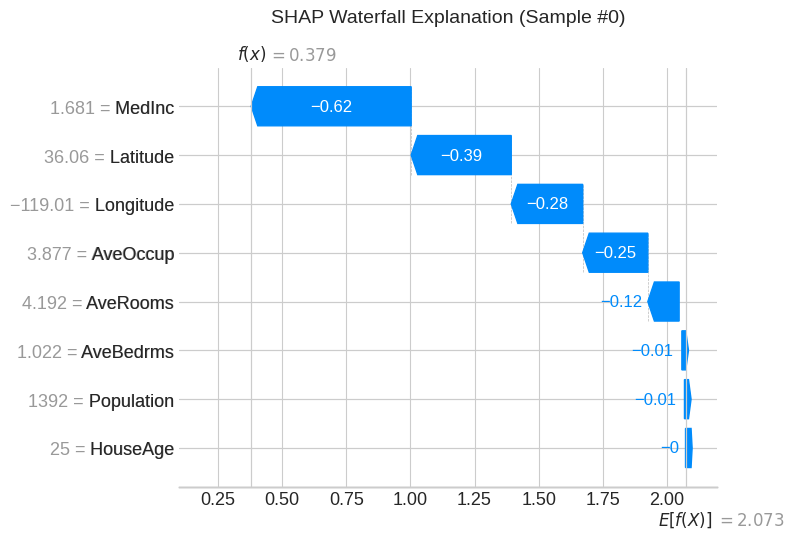

In [ ]:
sample_idx = 0
sample_actual = y_test.iloc[sample_idx] * 100_000
sample_pred = xgb_reg.predict(X_test.iloc[[sample_idx]])[0] * 100_000

print(f"Sample #{sample_idx}:")
print(f"  - Actual Valuation:    ${sample_actual:,.2f}")
print(f"  - Predicted Valuation: ${sample_pred:,.2f}")

plt.figure(figsize=(10, 5))
plt.title(f"SHAP Waterfall Explanation (Sample #{sample_idx})", fontsize=14, pad=15)
shap.plots.waterfall(shap_values[sample_idx], max_display=8, show=False)
plt.tight_layout()
plt.show()

<Figure size 900x500 with 0 Axes>

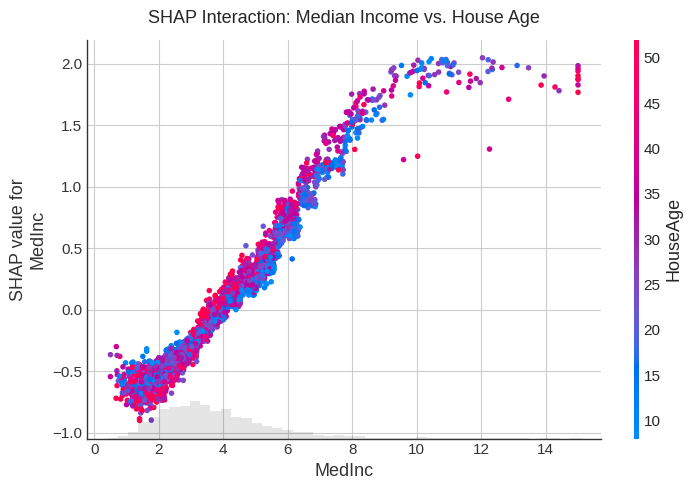

In [ ]:
# SHAP scatter plot highlighting feature interactions automatically
plt.figure(figsize=(9, 5))
shap.plots.scatter(shap_values[:, "MedInc"], color=shap_values[:, "HouseAge"], show=False)
plt.title("SHAP Interaction: Median Income vs. House Age", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

## Key Findings & Plain-English Interpretability Summary

1. **Median Income (`MedInc`) — Primary Global Driver:**
   - **Impact**: Dominates model predictions by a substantial margin.
   - **Direction**: Red points (high median block income) uniformly map to positive SHAP values, driving predicted valuations upward. Lower income heavily penalizes the valuation below baseline.
   - **Domain Logic**: Confirms economic intuition—purchasing power remains the single strongest pricing driver in residential real estate.

2. **Geographical Coordinates (`Latitude` & `Longitude`) — Spatial Drivers:**
   - **Impact**: Ranked #2 and #3 in feature importance.
   - **Direction**: Highlights distinct coastal clustering (e.g., coastal California coordinates positively lift valuation, whereas interior/inland valley coordinates pull valuation down).
   - **Domain Logic**: Location premium accounts for real-world coastal demand that pure house-specific metrics cannot capture.

3. **Average Occupancy (`AveOccup`) — Density Penalty:**
   - **Impact**: Higher occupancy per household exerts a negative influence on unit property value.
   - **Domain Logic**: Extremely high household occupancy rates typically signal multi-family density or lower average floor space per resident.